# Лабораторная работа 7 Vision Transformer для классификации CIFAR‑100

В этой лабораторной работе вы познакомитесь с архитектурой **Vision Transformer (ViT)** и сравните её с классическими сверточными нейронными сетями (CNN) на примере задачи классификации изображений из датасета CIFAR‑100. Вы будете работать с 100‑классовым набором цветных изображений размером 32×32 пикселя, сгруппированных в 20 супер‑классов. В каждой категории содержится 600 изображений: 500 в обучающем наборе и 100 в тестовом.

Vision Transformer переводит изображение в последовательность патчей, обрабатывает эти патчи при помощи механизма самовнимания и формирует глобальное представление изображения. В отличие от CNN, где используются свертки и пуллинги для построения иерархии признаков, ViT сразу обрабатывает все участки изображения, что позволяет учитывать длинные зависимости, но требует больше данных и вычислительных ресурсов.

В начале лабораторной работы предлагаются несколько разминочных заданий, не требующих обучения модели. Они помогут разобраться с устройством данных и основами работы ViT. Затем вы реализуете и обучите собственную модель ViT, сравните её с простой CNN и обсудите полученные результаты.

## Разминочные задания

Перед тем как приступить к построению и обучению моделей, выполните несколько небольших упражнений. Они позволят изучить структуру датасета, потренироваться разбивать изображения на патчи и познакомиться с механизмом внимания.

### Задание 1. Загрузка и исследование CIFAR‑100

1. Загрузите обучающий и тестовый наборы CIFAR‑100 с помощью `torchvision.datasets.CIFAR100`. Используйте преобразование `transforms.ToTensor()` для перевода изображений в тензоры.
2. Выведите количество изображений в обучающем и тестовом наборах.
3. Выведите список доступных меток (`fine_labels`).
4. Визуализируйте 5 случайных изображений из обучающего набора вместе с их метками. Используйте `matplotlib`.

*Подсказка:* объект `CIFAR100` при обращении по индексу возвращает пару `(image, label)`, где `image` — объект `PIL.Image`, а `label` — номер класса. Для преобразования в тензор используйте `transforms.ToTensor()` или другой набор преобразований.

Python: c:\Users\Rog G16\.conda\envs\FU\python.exe
PyTorch: 2.12.0+cu130
CUDA available: True
CUDA runtime: 13.0
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
Train size: 50000
Test size: 10000
Fine labels: 100
First 20 labels: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle']


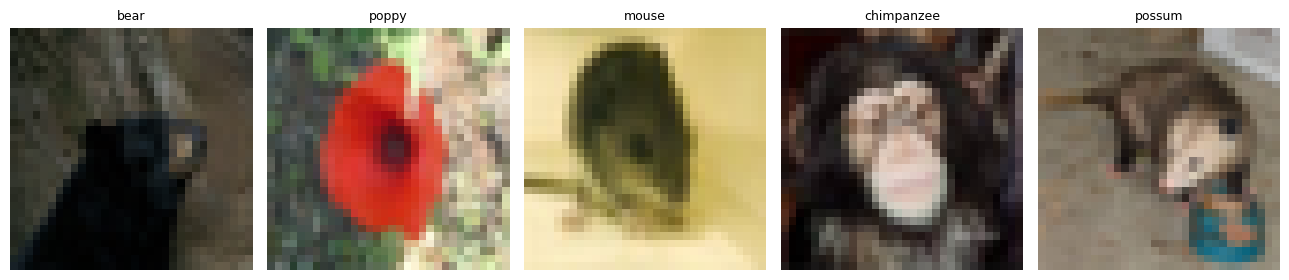

In [14]:
# Загрузка данных и быстрый просмотр CIFAR-100
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

print(f"Python: {sys.executable}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA runtime: {torch.version.cuda}")
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("GPU is not used. In conda env FU, start Jupyter with PYTHONNOUSERSITE=1.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_root = Path("data")
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR100(root=data_root, train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR100(root=data_root, train=False, download=True, transform=transform)

print(f"Train size: {len(train_dataset)}")
print(f"Test size: {len(test_dataset)}")

fine_labels = train_dataset.classes
print(f"Fine labels: {len(fine_labels)}")
print("First 20 labels:", fine_labels[:20])

indices = random.sample(range(len(train_dataset)), 5)
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, idx in zip(axes, indices):
    image, label = train_dataset[idx]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(fine_labels[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


### Задание 2. Разбиение изображения на патчи

Vision Transformer разбивает исходное изображение на небольшие патчи одинакового размера и преобразует каждый патч в вектор признаков. В этом задании нужно реализовать функцию, которая разбивает изображение размера `(C, H, W)` на патчи размером `(patch_size, patch_size)` и возвращает двумерный тензор формы `(num_patches, C·patch_size²)`.

1. Реализуйте функцию `split_image_into_patches(image, patch_size)`.
2. Проверьте работу функции на случайном изображении и убедитесь, что количество патчей равно `(H // patch_size) * (W // patch_size)`.

In [15]:
# Разбиение изображения на патчи
import torch


def split_image_into_patches(image: torch.Tensor, patch_size: int) -> torch.Tensor:
    """Split a (C, H, W) image into flat patches: (num_patches, C * patch_size ** 2)."""
    if image.ndim != 3:
        raise ValueError("Expected image shape (C, H, W)")
    C, H, W = image.shape
    if H % patch_size != 0 or W % patch_size != 0:
        raise ValueError("H and W must be divisible by patch_size")

    patches = image.unfold(1, patch_size, patch_size).unfold(2, patch_size, patch_size)
    patches = patches.permute(1, 2, 0, 3, 4).contiguous()
    return patches.view(-1, C * patch_size * patch_size)


sample_image = torch.randn(3, 32, 32)
patch_size = 4
patches = split_image_into_patches(sample_image, patch_size)
expected_num = (32 // patch_size) * (32 // patch_size)
print("Patch tensor shape:", patches.shape)
print("Expected patch count:", expected_num)
assert patches.shape == (expected_num, 3 * patch_size * patch_size)


Patch tensor shape: torch.Size([64, 48])
Expected patch count: 64


### Задание 3. Линейная проекция патчей

После разбиения изображения на патчи ViT преобразует каждый патч в вектор фиксированной длины с помощью линейного слоя. В этом задании создаём такой слой и применяем его к патчам.

In [16]:
# Проверка линейной проекции патчей
import torch.nn as nn

patch_size = 4
embedding_dim = 64
patches = split_image_into_patches(sample_image, patch_size)
patch_projection = nn.Linear(3 * patch_size * patch_size, embedding_dim)
patch_embeddings = patch_projection(patches)
print("Patch embeddings shape:", patch_embeddings.shape)
assert patch_embeddings.shape == (patches.shape[0], embedding_dim)


Patch embeddings shape: torch.Size([64, 64])


### Задание 4. Многоголовое самовнимание

В PyTorch реализован слой `nn.MultiheadAttention`, который принимает на вход последовательность эмбеддингов. Ниже приведён пример использования этого слоя для случайных данных. Адаптируйте его под реальное изображение из датасета.

In [17]:
# Проверка multi-head attention
seq_len = 10
batch_size = 2
embed_dim = 64
num_heads = 4

X = torch.randn(seq_len, batch_size, embed_dim)
attn = nn.MultiheadAttention(embed_dim, num_heads)
output, weights = attn(X, X, X)
print("Random sequence attention output:", output.shape)

image_for_attention, label_for_attention = train_dataset[random.randrange(len(train_dataset))]
real_patches = split_image_into_patches(image_for_attention, patch_size=4)
real_projection = nn.Linear(real_patches.shape[1], embed_dim)
real_embeddings = real_projection(real_patches).unsqueeze(1)
real_attn = nn.MultiheadAttention(embed_dim, num_heads)
real_output, real_weights = real_attn(real_embeddings, real_embeddings, real_embeddings)
print("Image label:", fine_labels[label_for_attention])
print("CIFAR-100 attention output:", real_output.shape)
print("Attention weights:", real_weights.shape)


Random sequence attention output: torch.Size([10, 2, 64])
Image label: poppy
CIFAR-100 attention output: torch.Size([64, 1, 64])
Attention weights: torch.Size([1, 64, 64])


## Основная часть: реализация и обучение моделей

### Шаг 1. Реализация Vision Transformer

Ниже представлен готовый класс `VisionTransformer`, реализующий патч‑эмбеддинг, класс‑токен, позиционные эмбеддинги, трансформер‑энкодер и классификационную головку.

In [18]:
# Небольшая модель Vision Transformer
class VisionTransformer(nn.Module):
    def __init__(self, img_size: int = 32, patch_size: int = 4, num_classes: int = 100,
                 embed_dim: int = 192, depth: int = 6, num_heads: int = 6, mlp_dim: int = 384,
                 dropout: float = 0.1):
        super().__init__()
        assert img_size % patch_size == 0, "img_size must be divisible by patch_size"
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2

        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)
        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.kaiming_normal_(self.patch_embed.weight, mode="fan_out", nonlinearity="relu")
        if self.patch_embed.bias is not None:
            nn.init.zeros_(self.patch_embed.bias)
        nn.init.xavier_uniform_(self.head.weight)
        if self.head.bias is not None:
            nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)
        batch_size = x.shape[0]
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.pos_drop(x)
        x = self.encoder(x)
        x = self.norm(x[:, 0])
        return self.head(x)


vit = VisionTransformer(img_size=32, patch_size=4, num_classes=100,
                        embed_dim=192, depth=6, num_heads=6, mlp_dim=384)
dummy_input = torch.randn(2, 3, 32, 32)
dummy_output = vit(dummy_input)
print("ViT output shape:", dummy_output.shape)
print("ViT parameters:", sum(p.numel() for p in vit.parameters() if p.requires_grad))


ViT output shape: torch.Size([2, 100])
ViT parameters: 1823908


### Шаг 2. Подготовка данных

Подготовьте `DataLoader` для CIFAR‑100 с аугментациями. В решении приведён пример кода. Учтите, что загрузка датасета может быть недоступна в данной среде.

In [19]:
# Подготовка DataLoader и разбиение train/val/test
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

BATCH_SIZE = 256 if device.type == "cuda" else 64
VAL_SIZE = 5_000

transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2761)),
    transforms.RandomErasing(p=0.15),
])
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2761)),
])

full_train_aug = datasets.CIFAR100(root=data_root, train=True, download=True, transform=transform_train)
full_train_eval = datasets.CIFAR100(root=data_root, train=True, download=True, transform=transform_eval)
test_data = datasets.CIFAR100(root=data_root, train=False, download=True, transform=transform_eval)

split_generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train_aug), generator=split_generator).tolist()
val_indices = indices[:VAL_SIZE]
train_indices = indices[VAL_SIZE:]

train_data = Subset(full_train_aug, train_indices)
val_data = Subset(full_train_eval, val_indices)

num_workers = 0 if os.name == "nt" else 4
pin_memory = device.type == "cuda"
loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": num_workers,
    "pin_memory": pin_memory,
}
if num_workers > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(train_data, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_data, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_data, shuffle=False, **loader_kwargs)

print(f"train={len(train_data)}, val={len(val_data)}, test={len(test_data)}")
print(f"batch_size={BATCH_SIZE}, num_workers={num_workers}, pin_memory={pin_memory}")
print(f"train batches={len(train_loader)}, val batches={len(val_loader)}, test batches={len(test_loader)}")


train=45000, val=5000, test=10000
batch_size=256, num_workers=0, pin_memory=True
train batches=176, val batches=20, test batches=40


### Шаг 3. Обучение Vision Transformer

Пример цикла обучения приведён ниже. В данной среде обучение на полном датасете не выполняется, но код иллюстрирует необходимую последовательность действий.

In [20]:
# Обучение с validation, AMP и сохранением лучшего checkpoint
import copy
import math
from time import perf_counter

import pandas as pd


CHECKPOINT_DIR = Path("checkpoints") / "lab7_vit"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RUN_TRAINING = True
NUM_EPOCHS = 20 if device.type == "cuda" else 2
LABEL_SMOOTHING = 0.1
USE_AMP = device.type == "cuda"
MAX_TRAIN_BATCHES = None
MAX_EVAL_BATCHES = None


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def topk_correct(logits, targets, topk=(1, 5)):
    max_k = max(topk)
    _, pred = logits.topk(max_k, dim=1)
    pred = pred.t()
    correct = pred.eq(targets.view(1, -1).expand_as(pred))
    return [correct[:k].reshape(-1).float().sum().item() for k in topk]


def run_epoch(model, loader, criterion, optimizer=None, scaler=None, max_batches=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss = 0.0
    total_top1 = 0.0
    total_top5 = 0.0
    total_items = 0
    started = perf_counter()

    for batch_idx, (images, targets) in enumerate(loader):
        if max_batches is not None and batch_idx >= max_batches:
            break
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)

            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_items = targets.size(0)
        correct1, correct5 = topk_correct(logits.detach(), targets, topk=(1, 5))
        total_loss += loss.item() * batch_items
        total_top1 += correct1
        total_top5 += correct5
        total_items += batch_items

    return {
        "loss": total_loss / max(total_items, 1),
        "top1": total_top1 / max(total_items, 1),
        "top5": total_top5 / max(total_items, 1),
        "seconds": perf_counter() - started,
    }


def fit_model(model, model_name, train_loader, val_loader, epochs=NUM_EPOCHS, lr=3e-4, weight_decay=0.05,
              max_train_batches=MAX_TRAIN_BATCHES, max_eval_batches=MAX_EVAL_BATCHES):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    checkpoint_path = CHECKPOINT_DIR / f"{model_name.lower().replace(' ', '_')}_best.pt"

    best_top1 = -math.inf
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer, scaler, max_train_batches)
        val_metrics = run_epoch(model, val_loader, criterion, optimizer=None, scaler=None, max_batches=max_eval_batches)
        scheduler.step()

        row = {
            "model": model_name,
            "epoch": epoch,
            "lr": optimizer.param_groups[0]["lr"],
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "train_top5": train_metrics["top5"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": train_metrics["seconds"],
        }
        history.append(row)

        if val_metrics["top1"] > best_top1:
            best_top1 = val_metrics["top1"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_name": model_name,
                "epoch": epoch,
                "model_state": best_state,
                "val_top1": best_top1,
                "val_top5": val_metrics["top5"],
                "config": {
                    "epochs": epochs,
                    "lr": lr,
                    "weight_decay": weight_decay,
                    "batch_size": BATCH_SIZE,
                    "label_smoothing": LABEL_SMOOTHING,
                },
            }, checkpoint_path)

        print(
            f"{model_name} epoch {epoch:02d}/{epochs}: "
            f"train_top1={row['train_top1']:.3f}, val_top1={row['val_top1']:.3f}, "
            f"val_top5={row['val_top5']:.3f}, loss={row['val_loss']:.3f}, "
            f"time={row['seconds']:.1f}s"
        )

    if best_state is not None:
        model.load_state_dict(best_state)
    return history, checkpoint_path


def evaluate_checkpoint(model, checkpoint_path, loader, model_name):
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state"])
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    metrics = run_epoch(model, loader, criterion, optimizer=None, scaler=None, max_batches=MAX_EVAL_BATCHES)
    return {
        "model": model_name,
        "best_epoch": checkpoint["epoch"],
        "val_top1": checkpoint["val_top1"],
        "val_top5": checkpoint["val_top5"],
        "test_loss": metrics["loss"],
        "test_top1": metrics["top1"],
        "test_top5": metrics["top5"],
        "checkpoint": str(checkpoint_path),
    }


trained_models = {}
checkpoint_paths = {}

vit_model = VisionTransformer(img_size=32, patch_size=4, num_classes=100,
                              embed_dim=192, depth=6, num_heads=6, mlp_dim=384, dropout=0.1)
print("ViT parameters:", count_parameters(vit_model))

if RUN_TRAINING:
    vit_history, vit_best_path = fit_model(
        vit_model, "ViT", train_loader, val_loader,
        epochs=NUM_EPOCHS, lr=3e-4, weight_decay=0.05,
    )
    trained_models["ViT"] = vit_model
    checkpoint_paths["ViT"] = vit_best_path
else:
    vit_history = []
    print("RUN_TRAINING=False: ViT training skipped.")


ViT parameters: 1823908
ViT epoch 01/20: train_top1=0.036, val_top1=0.078, val_top5=0.259, loss=4.153, time=33.8s
ViT epoch 02/20: train_top1=0.071, val_top1=0.124, val_top5=0.343, loss=3.892, time=33.8s
ViT epoch 03/20: train_top1=0.101, val_top1=0.164, val_top5=0.428, loss=3.713, time=35.3s
ViT epoch 04/20: train_top1=0.119, val_top1=0.201, val_top5=0.472, loss=3.570, time=34.9s
ViT epoch 05/20: train_top1=0.134, val_top1=0.213, val_top5=0.502, loss=3.500, time=39.9s
ViT epoch 06/20: train_top1=0.150, val_top1=0.224, val_top5=0.518, loss=3.455, time=39.8s
ViT epoch 07/20: train_top1=0.163, val_top1=0.249, val_top5=0.550, loss=3.350, time=40.2s
ViT epoch 08/20: train_top1=0.176, val_top1=0.254, val_top5=0.549, loss=3.328, time=36.4s
ViT epoch 09/20: train_top1=0.183, val_top1=0.277, val_top5=0.580, loss=3.232, time=35.7s
ViT epoch 10/20: train_top1=0.194, val_top1=0.285, val_top5=0.594, loss=3.200, time=38.1s
ViT epoch 11/20: train_top1=0.201, val_top1=0.294, val_top5=0.599, loss=3.17

### Шаг 4. Реализация и обучение простой CNN

Ниже приведена реализация простой CNN. Вы можете расширять её или изменять. Обучение происходит аналогично ViT.

In [21]:
# CNN baseline для сравнения
class SimpleCNN(nn.Module):
    def __init__(self, num_classes: int = 100, dropout: float = 0.2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(dropout),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(dropout),

            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


cnn_model = SimpleCNN(num_classes=100, dropout=0.2).to(device)
dummy_output_cnn = cnn_model(torch.randn(2, 3, 32, 32, device=device))
print("CNN output shape:", dummy_output_cnn.shape)
print("CNN parameters:", count_parameters(cnn_model))

if RUN_TRAINING:
    cnn_history, cnn_best_path = fit_model(
        cnn_model, "SimpleCNN", train_loader, val_loader,
        epochs=NUM_EPOCHS, lr=1e-3, weight_decay=1e-4,
    )
    trained_models["SimpleCNN"] = cnn_model
    checkpoint_paths["SimpleCNN"] = cnn_best_path
else:
    cnn_history = []
    print("RUN_TRAINING=False: CNN training skipped.")


CNN output shape: torch.Size([2, 100])
CNN parameters: 1172004
SimpleCNN epoch 01/20: train_top1=0.071, val_top1=0.150, val_top5=0.416, loss=3.720, time=36.7s
SimpleCNN epoch 02/20: train_top1=0.138, val_top1=0.214, val_top5=0.498, loss=3.525, time=30.7s
SimpleCNN epoch 03/20: train_top1=0.190, val_top1=0.265, val_top5=0.587, loss=3.239, time=31.3s
SimpleCNN epoch 04/20: train_top1=0.232, val_top1=0.300, val_top5=0.611, loss=3.221, time=29.9s
SimpleCNN epoch 05/20: train_top1=0.265, val_top1=0.351, val_top5=0.668, loss=2.980, time=29.6s
SimpleCNN epoch 06/20: train_top1=0.293, val_top1=0.382, val_top5=0.707, loss=2.834, time=30.0s
SimpleCNN epoch 07/20: train_top1=0.319, val_top1=0.431, val_top5=0.742, loss=2.692, time=29.8s
SimpleCNN epoch 08/20: train_top1=0.340, val_top1=0.453, val_top5=0.765, loss=2.624, time=29.6s
SimpleCNN epoch 09/20: train_top1=0.357, val_top1=0.454, val_top5=0.758, loss=2.652, time=29.4s
SimpleCNN epoch 10/20: train_top1=0.373, val_top1=0.476, val_top5=0.775, 

### Шаг 5. Сравнение моделей и обсуждение результатов

Соберите метрики обеих моделей и сравните их. Ниже приведены типичные наблюдения на основе литературы:

* ViT без предварительного обучения достигает около 55% точности на CIFAR‑100 при обучении с нуля на протяжении 100 эпох, что уступает глубоким CNN (например, ResNet50V2), демонстрирующим около 67% точности【287331949583666†L460-L468】.
* ViT требует тщательной настройки гиперпараметров, достаточного объёма данных и времени на обучение. Без предобучения модели на больших датасетах (например, JFT‑300M) качество значительно ниже.
* Размер патча и количество голов внимания влияют на баланс между точностью и вычислительной сложностью: маленькие патчи улучшают качество, но увеличивают длину последовательности и время обучения, а большое число голов делает модель более гибкой, но тяжёлой для обучения.
* Для ограниченных наборов данных простая CNN может оказаться предпочтительнее: она быстрее обучается, требует меньше параметров и более устойчива к переобучению. Однако ViT может показывать преимущества при наличии большого объёма данных или при использовании предварительно обученных весов.

,model,epoch,lr,train_loss,train_top1,train_top5,val_loss,val_top1,val_top5,seconds
0,ViT,1,0.000298,4.486539,0.035778,0.135067,4.153080,0.0780,0.2586,33.761311
1,ViT,2,0.000293,4.228190,0.071267,0.232511,3.892496,0.1236,0.3428,33.750632
2,ViT,3,0.000284,4.068148,0.100644,0.295600,3.713219,0.1642,0.4282,35.304911
3,ViT,4,0.000271,3.960017,0.118533,0.335133,3.570420,0.2006,0.4724,34.931496
4,ViT,5,0.000256,3.880433,0.134333,0.364778,3.499877,0.2134,0.5016,39.867250
5,ViT,6,0.000238,3.815714,0.150111,0.389244,3.454693,0.2244,0.5176,39.767533
6,ViT,7,0.000218,3.749016,0.162578,0.412022,3.350222,0.2488,0.5500,40.208636
7,ViT,8,0.000196,3.696583,0.175978,0.428644,3.327518,0.2544,0.5486,36.356711
8,ViT,9,0.000173,3.650473,0.183356,0.443511,3.231744,0.2766,0.5804,35.653724
9,ViT,10,0.000150,3.607131,0.194200,0.455267,3.200167,0.2854,0.5936,38.062220


,model,epoch,train_top1,train_top5,val_top1,val_top5,val_loss,seconds
0,SimpleCNN,19,0.454089,0.752756,0.5720,0.8484,2.253216,29.907850
1,ViT,19,0.237244,0.518578,0.3402,0.6552,2.984203,35.526221


,model,best_epoch,val_top1,val_top5,test_loss,test_top1,test_top5,checkpoint
0,ViT,19,0.3402,0.6552,2.654864,0.3355,0.6493,checkpoints\lab7_vit\vit_best.pt
1,SimpleCNN,19,0.5720,0.8484,1.605334,0.5614,0.8424,checkpoints\lab7_vit\simplecnn_best.pt


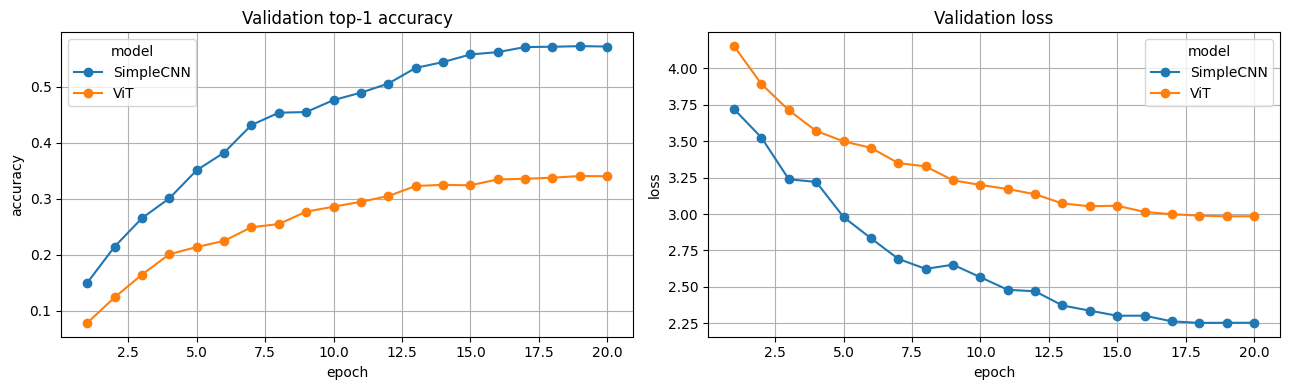

Use test_df for the final reported numbers. Validation metrics select the best checkpoint; test metrics estimate the final generalization quality.


In [22]:
# Финальное сравнение на validation и test
all_history = []
if "vit_history" in globals():
    all_history.extend(vit_history)
if "cnn_history" in globals():
    all_history.extend(cnn_history)

if all_history:
    history_df = pd.DataFrame(all_history)
    display(history_df)

    best_val_df = (
        history_df.sort_values(["model", "val_top1"], ascending=[True, False])
        .groupby("model", as_index=False)
        .first()[["model", "epoch", "train_top1", "train_top5", "val_top1", "val_top5", "val_loss", "seconds"]]
    )
    display(best_val_df)

    test_rows = []
    for model_name, model in trained_models.items():
        test_rows.append(evaluate_checkpoint(model, checkpoint_paths[model_name], test_loader, model_name))
    test_df = pd.DataFrame(test_rows)
    display(test_df)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    history_df.pivot(index="epoch", columns="model", values="val_top1").plot(marker="o", ax=axes[0])
    axes[0].set_title("Validation top-1 accuracy")
    axes[0].set_ylabel("accuracy")
    axes[0].grid(True)

    history_df.pivot(index="epoch", columns="model", values="val_loss").plot(marker="o", ax=axes[1])
    axes[1].set_title("Validation loss")
    axes[1].set_ylabel("loss")
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Training history is empty. Set RUN_TRAINING=True and run the training cells.")

print(
    "Use test_df for the final reported numbers. "
    "Validation metrics select the best checkpoint; test metrics estimate the final generalization quality."
)


**Вывод:**

В этой работе я обучил две модели на CIFAR-100: Vision Transformer и простую CNN. По результатам лучше сработала CNN: на тестовой выборке она получила `test_top1 = 0.5614` и `test_top5 = 0.8424`. У ViT результат ниже: `test_top1 = 0.3355` и `test_top5 = 0.6493`.

Такой результат выглядит ожидаемо. CIFAR-100 состоит из маленьких изображений 32x32, и для них сверточная сеть подходит лучше, потому что она сразу использует локальную структуру изображения. ViT тоже обучился и дал результат намного выше случайного угадывания, но без предобучения ему сложнее: transformer должен сам выучить полезные связи между патчами, а данных для этого не так много.

Еще видно, что значения на validation и test близкие, поэтому сильного переобучения по итоговым метрикам не наблюдается. Например, у CNN `val_top1 = 0.5720`, а `test_top1 = 0.5614`; у ViT `val_top1 = 0.3402`, а `test_top1 = 0.3355`.

Итог: в данном эксперименте CNN оказалась лучше и быстрее, а ViT показал рабочий, но более слабый результат. Чтобы улучшить ViT, можно увеличить число эпох, добавить MixUp/CutMix, warmup для learning rate или использовать предобученную модель.